# Does access to credit drive economic growth?

## The United States against Latin America, 1990–2023

**Research question.** Does access to private credit drive overall economic growth, and
does that relationship differ between the United States and Latin America?

**What I expected to find**, written down in [`plan.md`](plan.md) before pulling any data:

1. Credit growth does not unconditionally generate long-term wealth.
2. In Latin America, where financial systems are shallower, a marginal expansion of
   business credit should buy *more* growth, because it finances productive capital.
3. In the mature US system, credit expansion skews towards consumer and mortgage debt,
   which should yield lower long-run productivity returns.

**The honest caveat up front.** The World Bank reports private credit as a single
aggregate. It does not separate household borrowing from business borrowing — and the
distinction is not even clean in principle, since a vehicle bought on credit can be
household consumption or a taxi driver's capital equipment. The expectation above is a
claim about the *composition* of credit, and the data available here measures only its
*quantity*. That gap is the central limitation of this project, and I return to it in
the conclusion.

**Notebook structure**

| Step | Section |
|---|---|
| 0 | Setup and credentials |
| 1 | Pull the data from the World Bank API |
| 2 | Clean and reshape into a country-year panel |
| 3 | Build the derived variables |
| 4 | Charts |
| 5 | Regression models |
| 6 | Conclusion and limitations |

---
## 0. Setup and credentials

The analysis functions live in [`analysis.py`](analysis.py) so that the same code runs
both here and as a script; this notebook calls them and shows its work at each step.

**On credentials.** The World Bank Indicators API is open: no key, no registration. So
there is no secret to protect here. The project still reads configuration from the
environment through `python-dotenv` rather than hardcoding it, `.env` is listed in
`.gitignore`, and `.env.example` documents the variables with no values in them. If this
were extended to a gated source such as FRED, the key would arrive through the same path
and still never enter the repository.

In [1]:
import inspect

import pandas as pd
from IPython.display import Image, display

import analysis
import econ_style as es

es.apply()                      # Economist chart styling
pd.set_option("display.width", 120)

print("API base :", analysis.API_BASE)
print("API key  :", "loaded from environment" if analysis.API_KEY else "none needed for this endpoint")
print("Countries:", ", ".join(analysis.COUNTRIES))
print("Window   :", analysis.START, "-", analysis.END)

/Users/jhon/Documents/week6 /.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


API base : https://api.worldbank.org/v2
API key  : none needed for this endpoint
Countries: USA, ARG, BRA, CHL, COL, MEX, PER, LCN
Window   : 1990 - 2023


---
## 1. Pull the data from the World Bank API

Four indicators, eight geographies, pulled live over HTTP every time this notebook runs.
Nothing is read from a vendored file, so a reader cloning the repo gets the data from
source rather than from whatever snapshot happened to be committed.

| Series code | Variable | Units |
|---|---|---|
| `FS.AST.PRVT.GD.ZS` | Domestic credit to private sector | % of GDP |
| `NY.GDP.PCAP.KD.ZG` | Real GDP per capita growth | annual % |
| `NY.GDP.PCAP.KD` | Real GDP per capita | constant 2015 US$ |
| `SP.POP.TOTL` | Total population | persons |

Geographies: the **United States**; six Latin American economies — **Argentina, Brazil,
Chile, Colombia, Mexico, Peru**; and the regional aggregate **Latin America & Caribbean**
(`LCN`), which is pulled for reference but excluded from the regressions so that the same
economies are not counted twice.

### 1.1 The request

In [2]:
# The exact endpoint and query string, so the request is reproducible by hand.
code_ = "FS.AST.PRVT.GD.ZS"
print(analysis.indicator_url(code_))
print(analysis.request_params())

https://api.worldbank.org/v2/country/USA;ARG;BRA;CHL;COL;MEX;PER;LCN/indicator/FS.AST.PRVT.GD.ZS
{'format': 'json', 'date': '1989:2023', 'per_page': 1000}


### 1.2 The raw response

Taking one indicator first, to see what the API actually returns before any reshaping.
Element 0 of the JSON is pagination metadata; element 1 is the list of observations.

In [3]:
meta, rows = analysis.fetch_json(code_)
print("metadata:", meta)
print("\nfirst observation:")
rows[0]

metadata: {'page': 1, 'pages': 1, 'per_page': 1000, 'total': 280, 'sourceid': '2', 'lastupdated': '2026-07-13'}

first observation:


{'indicator': {'id': 'FS.AST.PRVT.GD.ZS',
  'value': 'Domestic credit to private sector (% of GDP)'},
 'country': {'id': 'AR', 'value': 'Argentina'},
 'countryiso3code': 'ARG',
 'date': '2023',
 'value': 15.3570823376105,
 'unit': '',
 'obs_status': '',
 'decimal': 1}

Note `"pages": 1`. The API paginates at `per_page`, and a silently truncated response
would drop country-years off the end of the panel with no visible symptom, so the fetch
function asserts on it rather than trusting it:

In [4]:
print(inspect.getsource(analysis.fetch_json))

def fetch_json(code: str) -> tuple:
    """Raw (metadata, observations) straight from the API, before any reshaping."""
    response = requests.get(indicator_url(code), params=request_params(), timeout=60)
    response.raise_for_status()
    payload = response.json()
    if isinstance(payload, list) and payload and "message" in (payload[0] or {}):
        raise RuntimeError(f"World Bank API error for {code}: {payload[0]['message']}")
    meta, rows = payload
    # The API paginates at per_page; silently truncating would drop country-years
    # off the end of the panel without any visible symptom, so assert instead.
    assert meta["pages"] == 1, f"{code}: response paginated, raise per_page"
    return meta, rows



### 1.3 All four indicators

`load_raw()` calls the API once per indicator and joins the results on (country, year).
It writes `data/raw_worldbank.csv` as an *output* for inspection — there is deliberately
no read-through cache, since that would let the notebook run without ever contacting the
API and quietly break the reproducibility claim.

In [5]:
raw = analysis.load_raw()
print(f"{len(raw)} country-year rows, {raw['iso3'].nunique()} geographies, "
      f"{raw['year'].min()}-{raw['year'].max()}")
raw.head()

280 country-year rows, 8 geographies, 1989-2023


,iso3,year,credit_gdp,gdp_pc_growth,gdp_pc,population
34,ARG,1989,39.717495,-8.567869,8445.410092,32270948
33,ARG,1990,15.601695,-3.911192,8115.093864,32755901
32,ARG,1991,12.587203,7.575135,8729.823185,33230294
31,ARG,1992,15.445335,6.453324,9293.186923,33693527
30,ARG,1993,18.284605,6.752115,9920.673586,34152717


---
## 2. Clean and reshape

Three things happen here, all specified in `plan.md` §3.

**Short gaps are forward-filled, long ones are not.** A two-year cap bridges a missed WDI
vintage without inventing a decade of synthetic variation. Interpolation would be the
alternative, but it leaks future information backwards into the lag structure.

**Country-years missing credit or growth are dropped.** No imputation of the dependent
variable.

**One year of lead-in is pulled before 1990** so that the first difference and the
one-year lag are defined in 1990 rather than lost to differencing.

First, how much is actually missing:

In [6]:
missing = (raw.set_index(["iso3", "year"]).isna().groupby("iso3").sum()
             .rename(columns=lambda c: f"missing_{c}"))
missing

,missing_credit_gdp,missing_gdp_pc_growth,missing_gdp_pc,missing_population
iso3,,,,
ARG,1,0,0,0
BRA,0,0,0,0
CHL,12,0,0,0
COL,1,0,0,0
LCN,6,0,0,0
MEX,8,0,0,0
PER,0,0,0,0
USA,0,0,0,0


Mexico and Chile are the gaps that matter: the WDI credit series starts in 1997 for Mexico
and 2001 for Chile. This makes the panel **unbalanced**, which matters for the regional
average in Chart 1 — its country composition changes in those years.

In [7]:
panel = analysis.build_panel(raw)
annual = analysis.country_panel(panel)      # drops the LCN aggregate

coverage = (annual.groupby("iso3")
            .agg(n_years=("year", "size"), first=("year", "min"), last=("year", "max"),
                 credit_min=("credit_gdp", "min"), credit_max=("credit_gdp", "max"),
                 mean_growth=("gdp_pc_growth", "mean"))
            .round(1))
coverage

,n_years,first,last,credit_min,credit_max,mean_growth
iso3,,,,,,
ARG,34,1990,2023,9.7,24.9,1.4
BRA,34,1990,2023,27.7,134.1,1.1
CHL,23,2001,2023,73.1,123.5,2.4
COL,34,1990,2023,20.9,52.0,1.9
MEX,27,1997,2023,12.2,36.9,0.8
PER,34,1990,2023,7.0,55.3,2.5
USA,34,1990,2023,114.8,219.1,1.6


The level gap is the first striking fact in the data, before any modelling: US private
credit never falls below 115% of GDP, while Argentina's never rises above 25%. These are
not economies at different points on the same curve so much as different regimes.

---
## 3. Derived variables

| Variable | Definition | Why |
|---|---|---|
| `credit_lag` | Credit/GDP at *t−1* | Predetermined depth. Removes the mechanical same-period simultaneity — though not endogeneity, since growth is serially correlated |
| `d_credit` | Credit/GDP at *t* − at *t−1* | Credit *expansion*, the flow measure the hypothesis is about |
| `latam` | 1 for the six LatAm economies, 0 for the USA | The comparison of interest |
| `hyper` | Hyperinflation flag | See below |

**The hyperinflation flag.** Under hyperinflation the price level moves far faster than
the stock of bank credit can be revalued, so credit/GDP swings by tens of points a year
with no change in real lending. Brazil before the 1994 Real Plan and Argentina before the
1991 Convertibility Plan are the two episodes in this sample. Brazil 1990–95 alone
produces changes in credit/GDP from −86 to +50 points. In OLS, leverage grows with the
squared deviation of a regressor from its mean, so a handful of measurement artifacts can
drive the slope on their own — hence a robustness check that drops them.

In [8]:
annual.loc[annual["d_credit"].abs() > 15,
           ["iso3", "year", "credit_gdp", "d_credit", "gdp_pc_growth", "hyper"]
          ].sort_values("d_credit").round(2)

,iso3,year,credit_gdp,d_credit,gdp_pc_growth,hyper
68,BRA,1990,42.08,-85.66,-6.04,True
64,BRA,1994,69.52,-64.59,4.21,True
246,USA,2022,187.09,-32.04,1.94,False
63,BRA,1995,43.49,-26.03,2.63,False
33,ARG,1990,15.60,-24.12,-3.91,True
260,USA,2008,185.13,-21.23,-0.83,False
85,CHL,2008,100.17,16.10,2.76,False
248,USA,2020,217.26,22.53,-2.48,False
66,BRA,1992,84.47,39.31,-2.19,True
65,BRA,1993,134.11,49.65,3.24,True


Every swing above 15 points is either a hyperinflation year or the 2008 and 2020 crises —
the two moments when GDP, the *denominator*, moved violently. This is worth holding onto:
much of the variation in the key regressor is not variation in lending at all.

### 3.1 Regional aggregate

For the time-series chart the six LatAm economies are collapsed into one series using
**population weights**, so that Peru does not count as much as Brazil:

$$\text{LatAm Credit Ratio}_t = \frac{\sum_i \text{Credit/GDP}_{i,t} \times \text{Pop}_{i,t}}{\sum_i \text{Pop}_{i,t}}$$

This is a weighted mean of ratios, not the ratio of regional totals; the two differ, and
the latter would be preferable if the WDI published regional credit stocks in levels.

In [9]:
regional = analysis.regional_series(panel)
regional.groupby("region").tail(2).round(1)

,year,credit_gdp,gdp_pc_growth,n_countries,region,credit_gdp_roll5,gdp_pc_growth_roll5
66,2022,52.9,3.3,6,LatAm,52.0,0.7
67,2023,52.4,1.5,6,LatAm,52.7,0.8
32,2022,187.1,1.9,1,USA,200.3,2.0
33,2023,191.1,2.1,1,USA,201.9,1.9


### 3.2 Five-year panel

Annual growth rates are dominated by the business cycle, but the mechanism under test —
credit financing capital accumulation — operates over years. Collapsing to **non-overlapping
five-year averages** is the standard unit of observation in the empirical growth literature
(Levine, Loayza & Beck 2000; Beck & Levine 2004). It also attenuates the
recession-denominator problem, since output gaps largely close within five years.

Depth is measured at the *start* of each period, so the conditioning variable is
predetermined rather than contemporaneous with the outcome.

In [10]:
quin = analysis.quinquennial(annual)
print(f"{len(quin)} country-period observations")
quin.head(8).round(2)

46 country-period observations


,iso3,period,period_label,year_mid,growth,credit_initial,d_credit,latam,hyper
0,ARG,0,1990-94,1992.0,4.26,15.60,4.68,1,True
1,ARG,1,1995-99,1997.0,1.01,19.96,4.93,1,False
2,ARG,2,2000-04,2002.0,-0.71,23.89,-14.21,1,False
3,ARG,3,2005-09,2007.0,3.74,10.65,1.76,1,False
4,ARG,4,2010-14,2012.0,1.94,12.69,1.13,1,False
5,ARG,5,2015-19,2017.0,-1.11,14.41,0.06,1,False
6,ARG,6,2020-23,2021.5,0.87,15.75,-0.39,1,False
7,BRA,0,1990-94,1992.0,-0.29,42.08,27.44,1,True


---
## 4. Charts

All four are drawn in the house style of *The Economist* — red corner flag, left-aligned
title block, horizontal-only gridlines, value labels on the right, source line in the
gutter. The styling lives in [`econ_style.py`](econ_style.py); the two-colour series
palette was checked against a colour-vision-deficiency simulator before use.

Every chart carries a title, axis labels with units, and the data source.

### Chart 1 — Credit depth and growth over time

Private credit (% of GDP, left scale, solid) against real GDP per person (5-year average
% change, right scale, dashed), 1990–2023.

**Read this one with care.** With two y-scales the eye reads crossings and relative slopes
as meaningful when they are an artifact of where the axis limits were set. Solid/dashed
marks which scale each line belongs to and every line is labelled at its right-hand end,
but Chart 1b below plots the same data on separate scales and is the safer version for
drawing conclusions about levels.

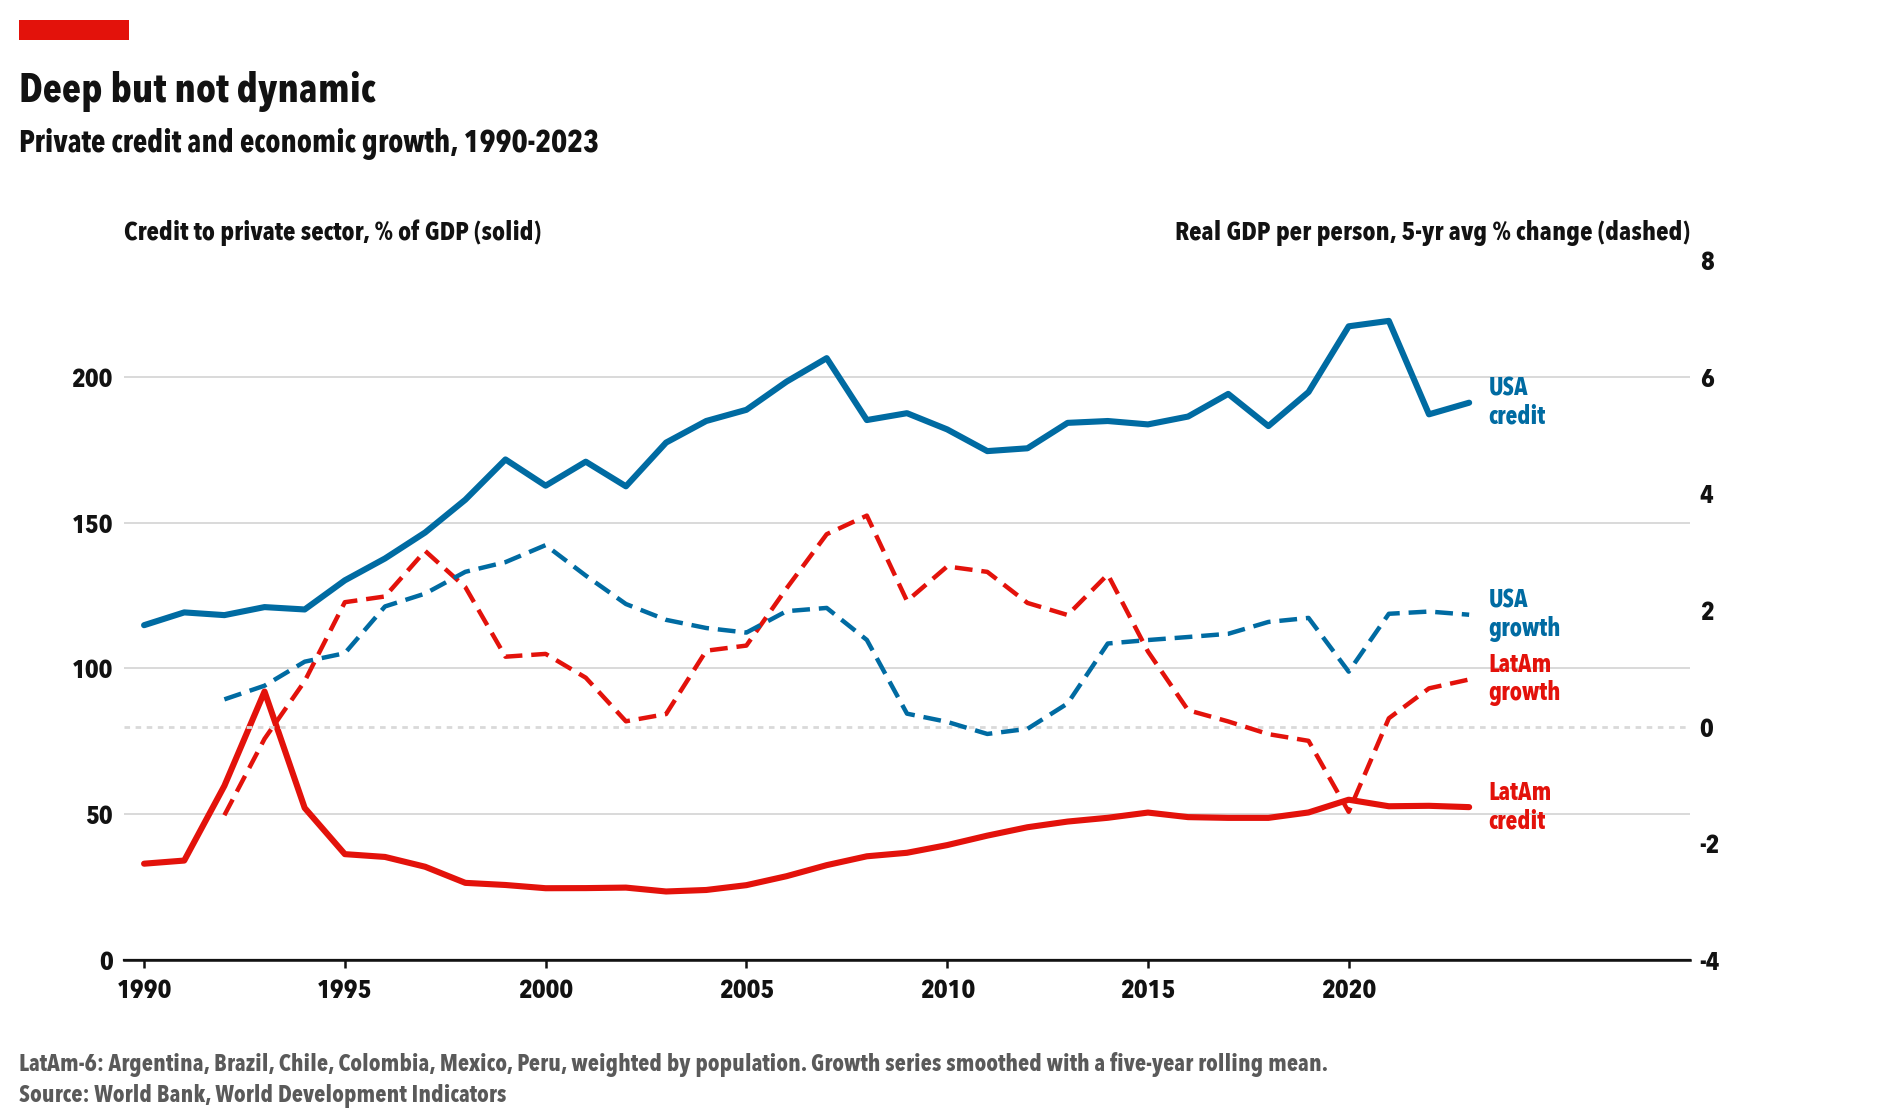

In [11]:
analysis.chart1_dual_axis(regional)
display(Image(filename="figures/chart1_dual_axis.png"))

US private credit roughly doubled from 115% to 190% of GDP across these three decades.
Latin American credit depth ended the period around 52% — barely above where it started
once the Brazilian hyperinflation distortion at the left edge is discounted. Neither
region's growth trend shows anything that tracks those credit paths. US growth drifts
*down* over exactly the stretch when its credit deepened most.

### Chart 1b — The same data, separate scales

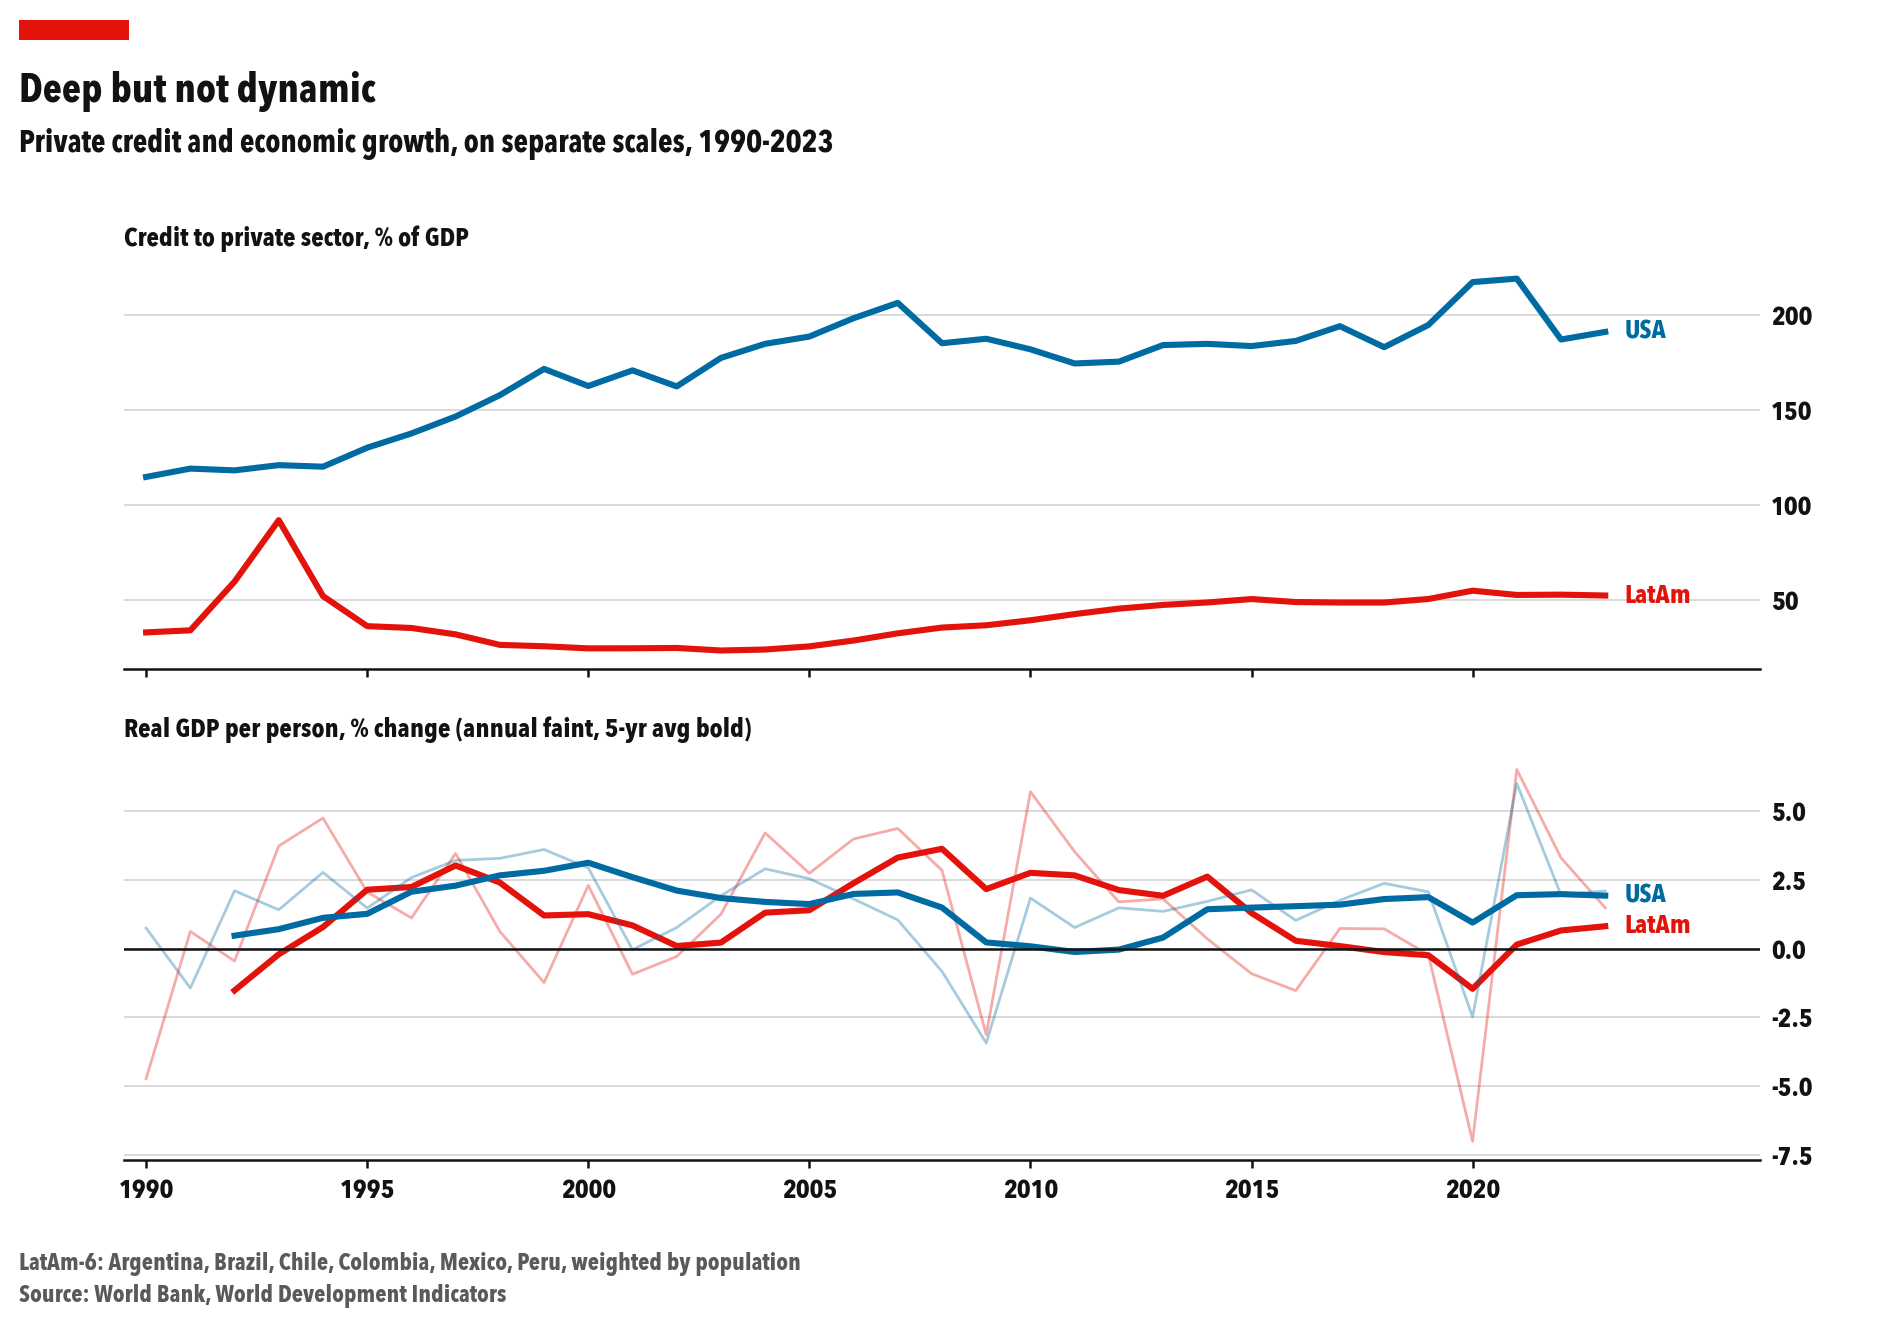

In [12]:
analysis.chart1b_panels(regional)
display(Image(filename="figures/chart1b_panels.png"))

### Chart 2 — Credit expansion against growth

Each point is one country-year: the annual change in credit/GDP (percentage points)
against real GDP per capita growth (%). Separate OLS trendlines are fitted for each
region, matching the baseline regression in section 5.

Hyperinflation country-years are drawn **hollow** — they are kept in the baseline fit for
fidelity to the plan, but they are exactly the high-leverage points a reader should
discount.

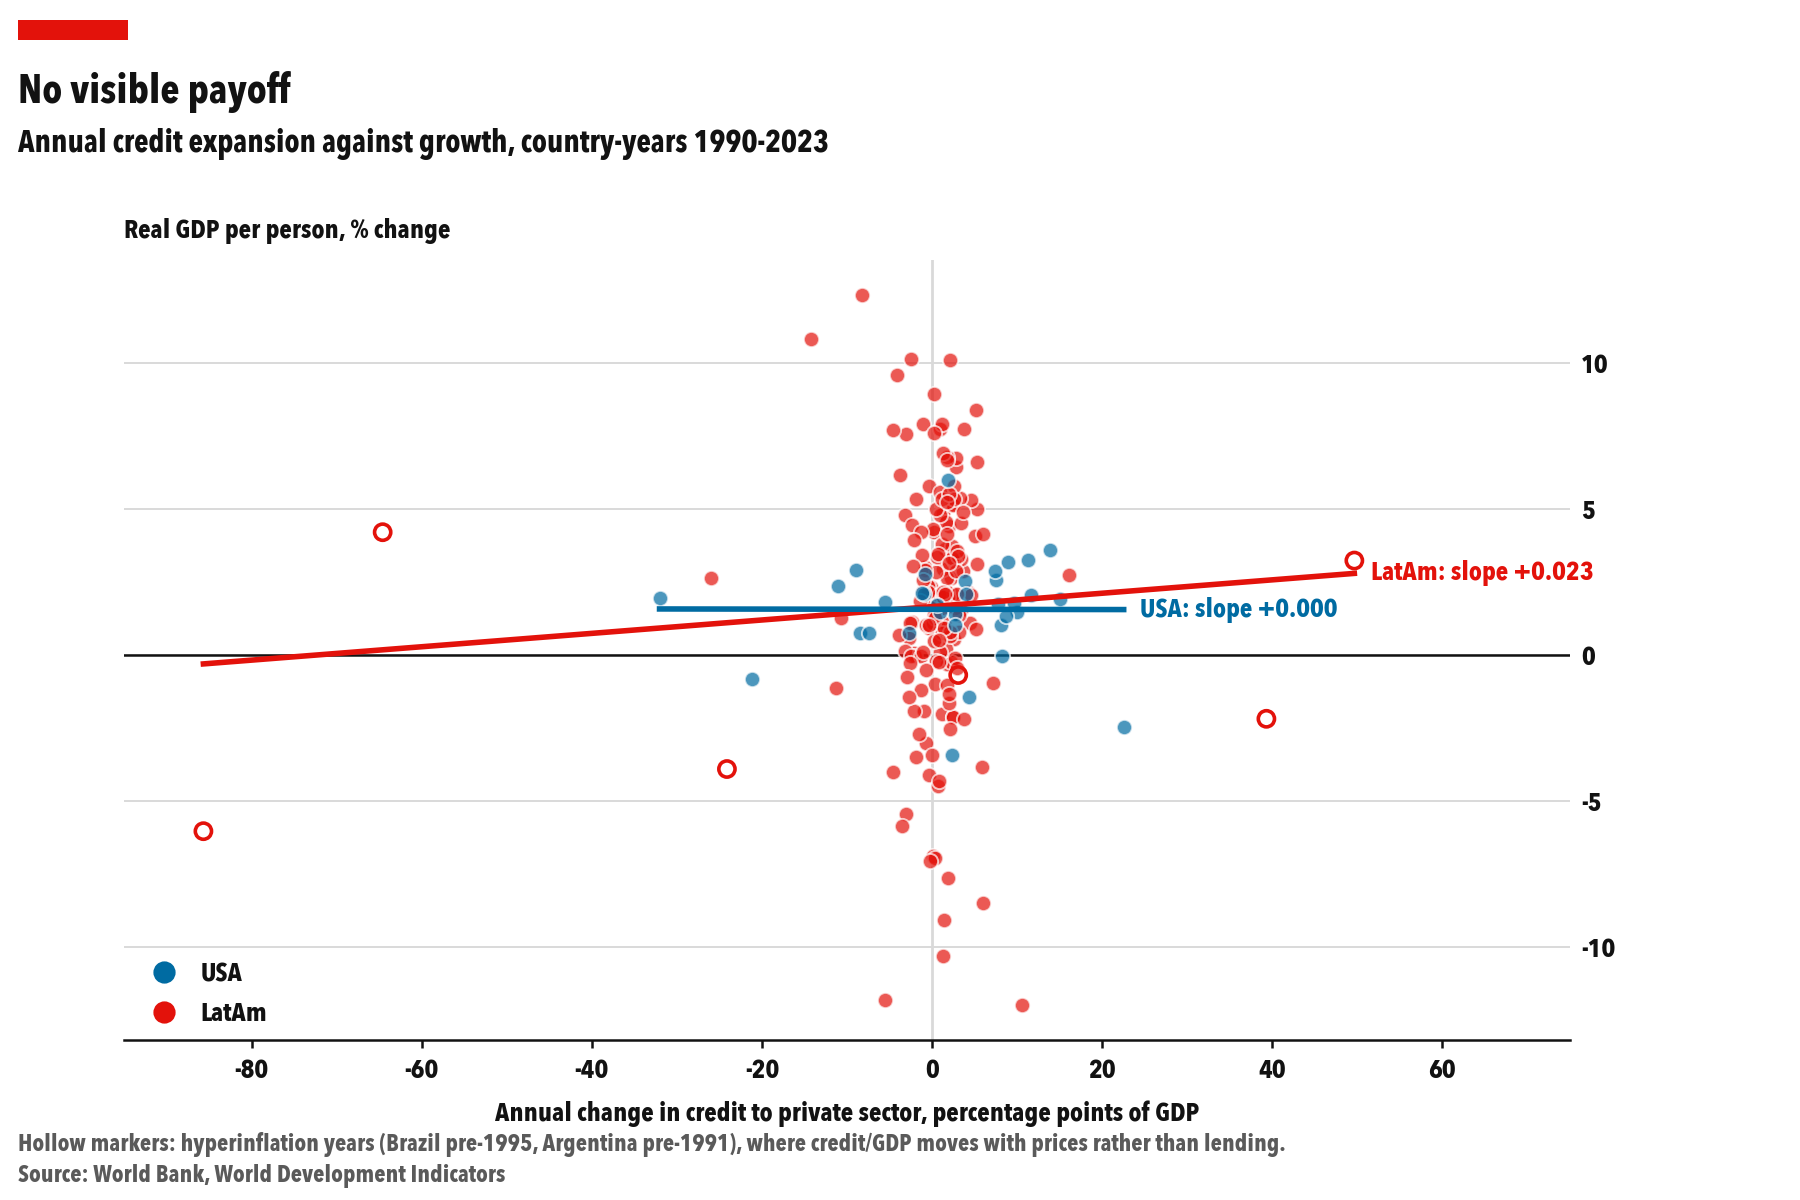

In [13]:
d_model = annual.dropna(subset=["d_credit", "credit_lag"])
analysis.chart2_scatter(d_model)
display(Image(filename="figures/chart2_scatter.png"))

Both trendlines are nearly flat. The LatAm slope of +0.023 means a 10-point surge in
credit/GDP — an enormous move — is associated with roughly a fifth of a percentage point
of extra growth. The vertical spread at ΔCredit ≈ 0 spans from −12% to +12% growth, which
is the real message: whatever drives growth in these economies, it is not in this chart.

### Chart 3 — Does depth show diminishing returns?

The plan predicted diminishing returns to credit at higher baseline debt levels. This
tests it directly: financial depth at the start of each five-year period against average
growth over that period, with a quadratic fit. Arcand, Berkes & Panizza (2015) find the
finance–growth relationship turns negative above roughly 100% of GDP — the "too much
finance" result.

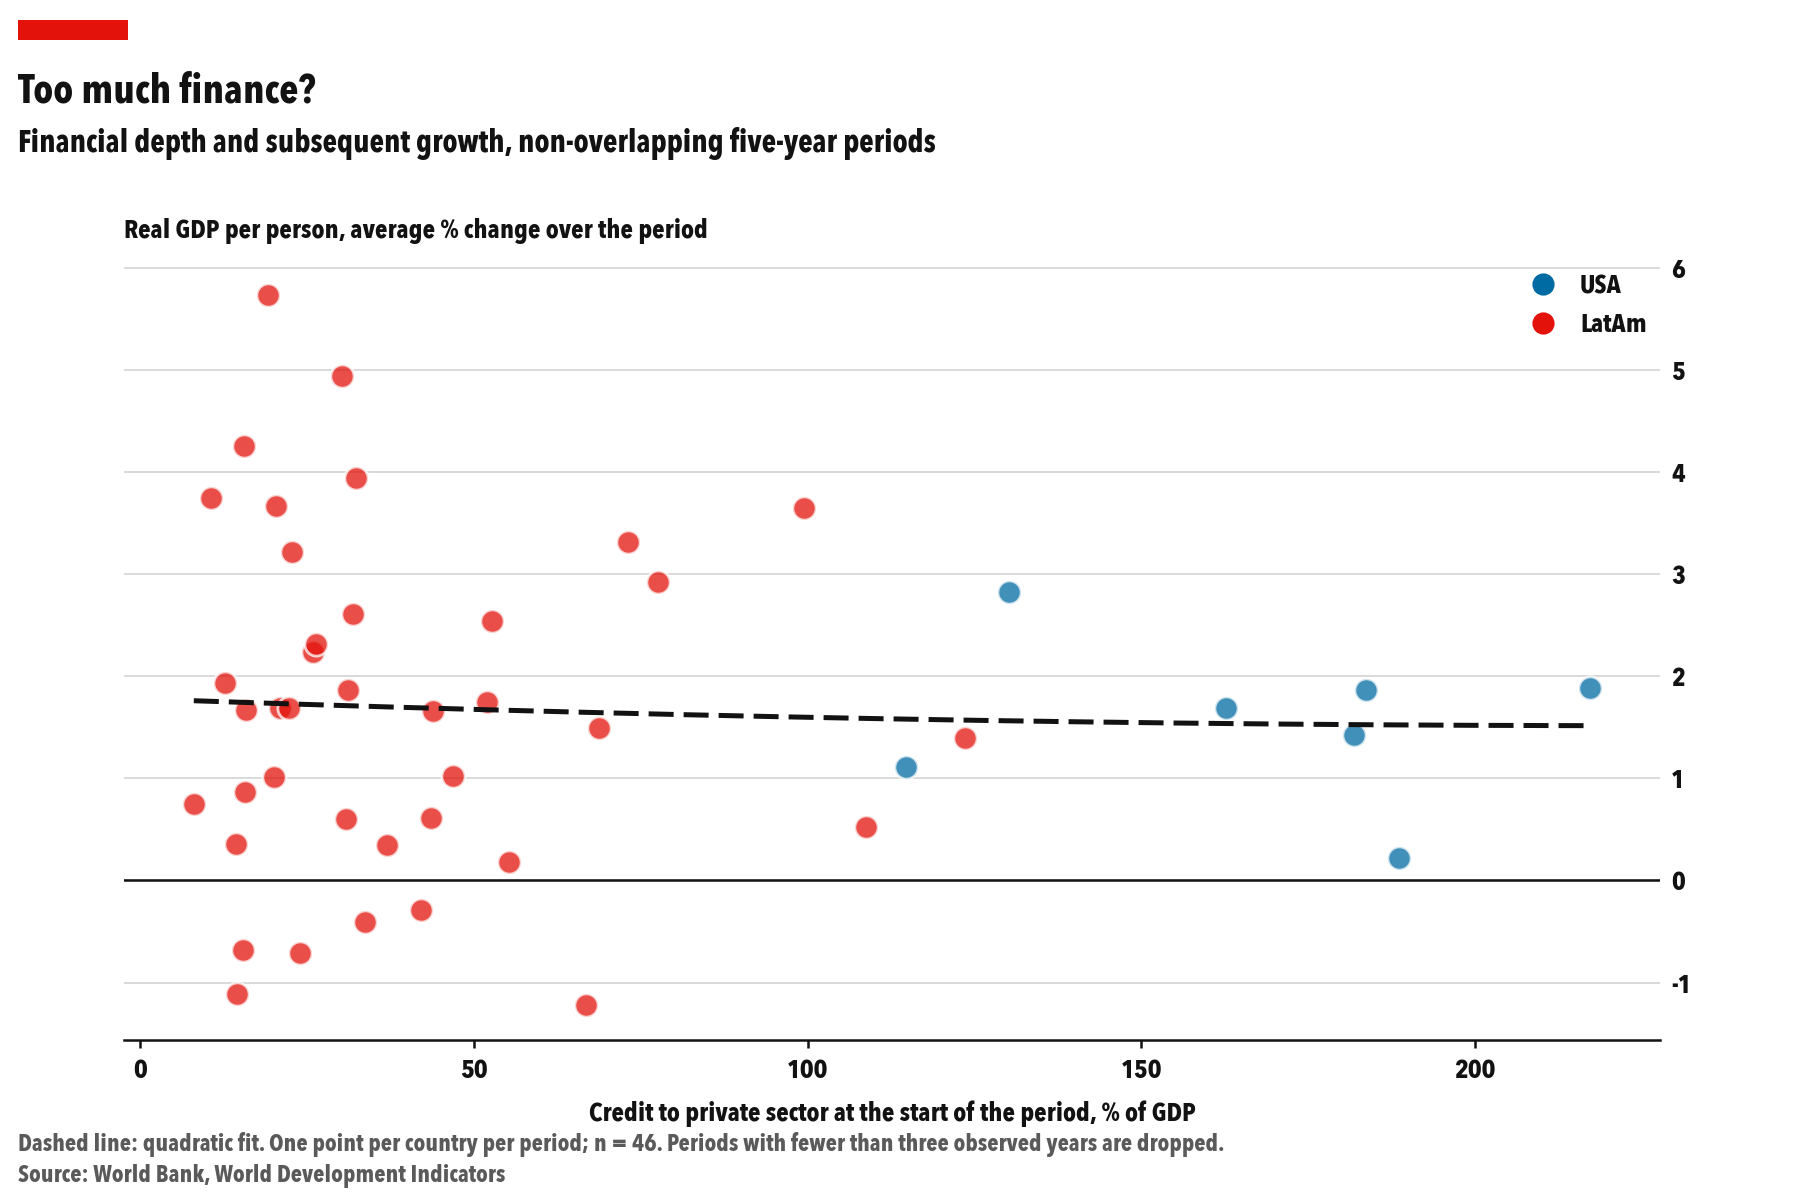

In [14]:
analysis.chart3_too_much_finance(quin, None)
display(Image(filename="figures/chart3_too_much_finance.png"))

The fitted curve is essentially a flat line. There is no hump and no visible turning
point within the observed range, so this sample does not reproduce the "too much finance"
result — but note the US points sit in a cluster far to the right with nothing nearby, so
the curvature at high depth is identified off very few observations.

---
## 5. Regression models

The model specified in `plan.md` §4:

$$\text{Growth}_{i,t} = \alpha + \beta_1 \text{Credit/GDP}_{i,t-1} + \beta_2 \Delta\text{Credit/GDP}_{i,t} + \beta_3 \text{LatAm}_i + \beta_4 (\Delta\text{Credit/GDP}_{i,t} \times \text{LatAm}_i) + \epsilon_{i,t}$$

- $\beta_2$ is the growth effect of credit expansion in the **USA** (the omitted category).
- $\beta_4$ tests whether that effect is **different in Latin America**.
- $\beta_2 + \beta_4$ is the implied **effect in Latin America**, which is the quantity
  the hypothesis is actually about — and it needs the covariance between the two terms,
  not just the sum of the point estimates.

**What this design can and cannot deliver.** The finance-growth literature (King & Levine
1993; Levine 2005 for the survey) established a robust partial correlation between
financial depth and growth, but identifying a *causal* effect needs an instrument for
credit supply (Rajan & Zingales 1998 use industry-level external-finance dependence) or a
natural experiment. This has neither. Read everything below as conditional correlation.

Seven specifications are estimated so that the conclusion does not rest on one set of
modelling choices.

In [15]:
d, models = analysis.fit_models(annual, quin)

for name, res in models.items():
    print(f"{name:34s} N={int(res.nobs):3d}  R2={res.rsquared:.3f}")

Pooled OLS (plan baseline)         N=217  R2=0.003
Pooled OLS, clustered by country   N=217  R2=0.003
Two-way fixed effects              N=217  R2=0.619
Two-way FE, excluding 2020-22      N=196  R2=0.487
Excluding hyperinflation years     N=211  R2=0.002
Five-year averages                 N= 46  R2=0.097
Quadratic in depth                 N=217  R2=0.004


### 5.1 The baseline specified in the plan

Pooled OLS with heteroskedasticity-robust (HC1) standard errors — growth volatility in
Argentina is far higher than in the USA, so homoskedastic errors would be wrong.

In [16]:
print(models["Pooled OLS (plan baseline)"].summary())

                            OLS Regression Results                            
Dep. Variable:          gdp_pc_growth   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.015
Method:                 Least Squares   F-statistic:                    0.1249
Date:                Fri, 02 Oct 2026   Prob (F-statistic):              0.973
Time:                        17:05:23   Log-Likelihood:                -598.81
No. Observations:                 217   AIC:                             1208.
Df Residuals:                     212   BIC:                             1225.
Df Model:                           4                                         
Covariance Type:                  HC1                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          1.9374      1.644      1.

Nothing is significant and $R^2 = 0.003$: the model explains essentially none of the
variation in growth. $\beta_4 = +0.024$ has the predicted sign but a p-value of 0.61.

### 5.2 All seven specifications

Reporting $\beta_2$ (USA) and $\beta_2 + \beta_4$ (LatAm) with 95% intervals.

In [17]:
rows = []
for name, res in models.items():
    eff = analysis.marginal_effects(res)
    row = {"specification": name, "N": int(res.nobs), "R2": round(res.rsquared, 3)}
    for region in ("USA", "LatAm"):
        if region in eff:
            coef, lo, hi, p = eff[region]
            row[f"{region}"] = round(coef, 3)
            row[f"{region} 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
            row[f"{region} p"] = round(p, 3)
    rows.append(row)

pd.DataFrame(rows).set_index("specification")

,N,R2,USA,USA 95% CI,USA p,LatAm,LatAm 95% CI,LatAm p
specification,,,,,,,,
Pooled OLS (plan baseline),217,0.003,-0.002,"[-0.064, 0.059]",0.945,0.022,"[-0.047, 0.090]",0.536
"Pooled OLS, clustered by country",217,0.003,-0.002,"[-0.012, 0.007]",0.651,0.022,"[-0.010, 0.053]",0.181
Two-way fixed effects,217,0.619,0.073,"[0.050, 0.097]",0.000,-0.007,"[-0.031, 0.017]",0.584
"Two-way FE, excluding 2020-22",196,0.487,0.053,"[0.003, 0.102]",0.037,0.002,"[-0.024, 0.028]",0.897
Excluding hyperinflation years,211,0.002,-0.002,"[-0.064, 0.061]",0.962,-0.050,"[-0.249, 0.150]",0.627
Five-year averages,46,0.097,0.017,"[-0.019, 0.054]",0.354,0.053,"[-0.008, 0.114]",0.090
Quadratic in depth,217,0.004,0.019,"[-0.041, 0.079]",0.539,NaN,NaN,NaN


### Chart 4 — The same table, as a picture

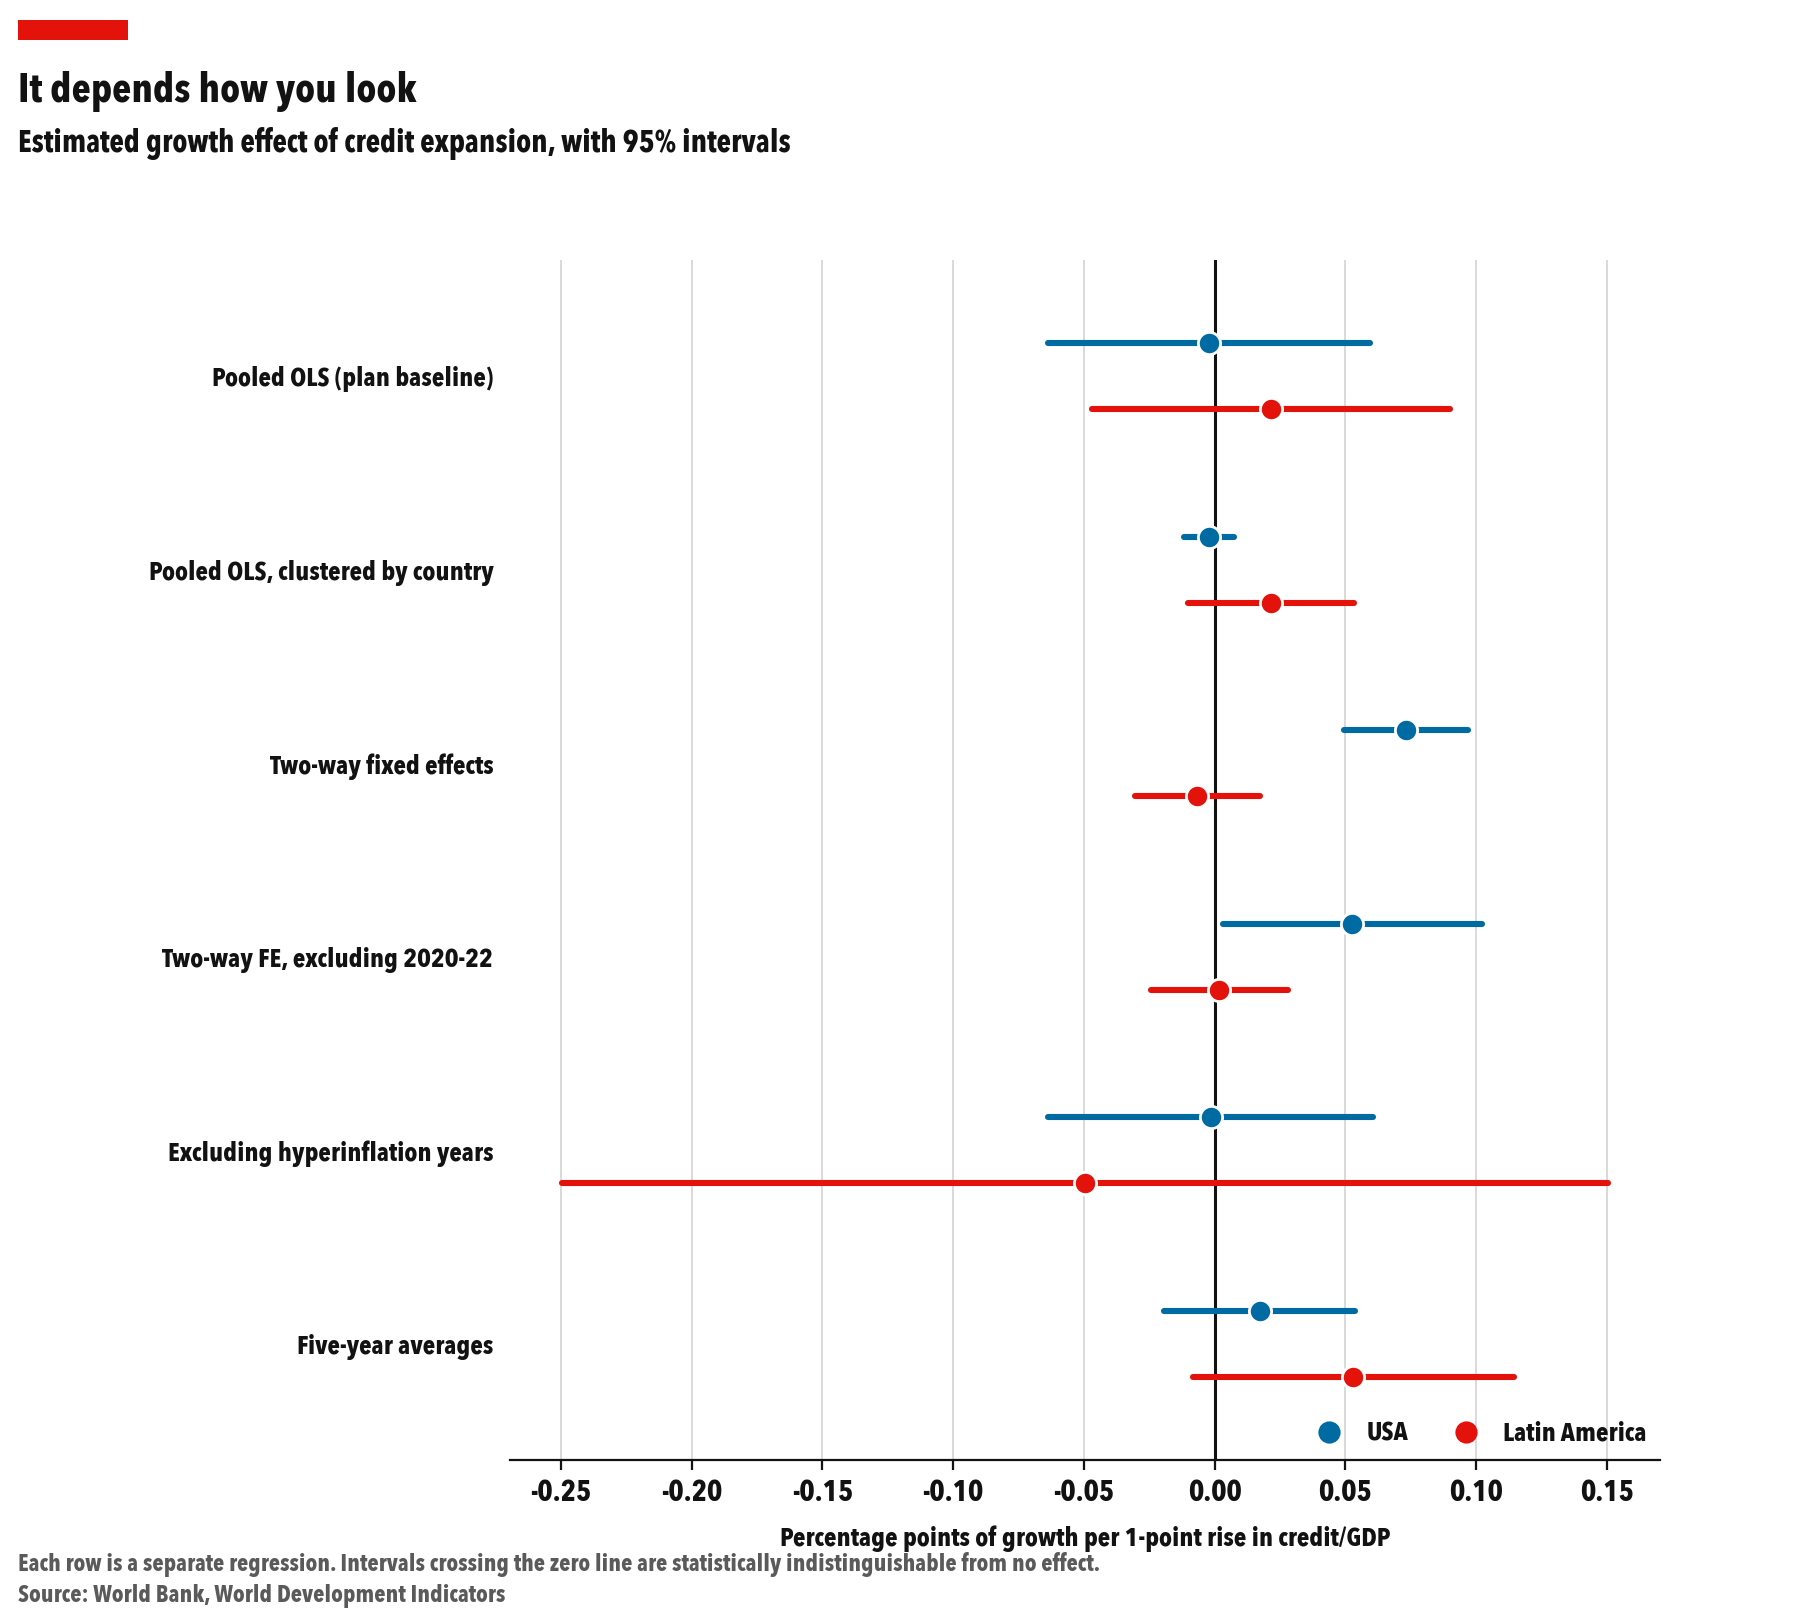

In [18]:
analysis.chart4_coefficients(models)
display(Image(filename="figures/chart4_coefficients.png"))

### 5.3 The one result that isn't zero

Adding country and year fixed effects — absorbing fixed institutional differences and
global shocks like 2009 and 2020 — produces the only significant coefficient in the set.
It is **positive for the USA**, which is the opposite of what the plan predicted.

In [19]:
fe = models["Two-way fixed effects"]
print(fe.summary().tables[1].as_text()[:1200])

                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -4.0401      2.182     -1.851      0.064      -8.317       0.237
C(iso3)[T.BRA]      0.1837      0.317      0.579      0.563      -0.438       0.805
C(iso3)[T.CHL]      1.8253      0.541      3.373      0.001       0.765       2.886
C(iso3)[T.COL]      0.5656      0.157      3.593      0.000       0.257       0.874
C(iso3)[T.MEX]     -0.7149      0.156     -4.592      0.000      -1.020      -0.410
C(iso3)[T.PER]      1.2635      0.097     12.972      0.000       1.073       1.454
C(iso3)[T.USA]      2.2019      1.262      1.745      0.081      -0.271       4.675
C(year)[T.1991]     4.8362      3.103      1.559      0.119      -1.246      10.918
C(year)[T.1992]     5.0439      2.159      2.336      0.019       0.812       9.275
C(year)[T.1993]     7.5423      2.851      2.646      0.008       1.955     

/Users/jhon/Documents/week6 /.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/jhon/Documents/week6 /.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/jhon/Documents/week6 /.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)
/Users/jhon/Documents/week6 /.venv/lib/python3.9/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 6
  warnings.warn('covariance of constraints does not have full '


Three reasons not to lean on it:

1. **Seven clusters.** The p-value comes from a cluster-robust variance estimator, which
   is consistent in the *number of clusters*. Seven is far below the ~40 rule of thumb
   (Cameron & Miller 2015); the estimator is known to be badly downward-biased there, so
   the significance is not credible at face value. A wild cluster bootstrap would be the
   appropriate fix.
2. **Pandemic leverage.** US credit/GDP rose 22 points in 2020 as firms drew down credit
   lines, then fell 32 points by 2022 as they repaid — alongside the largest output swing
   in the sample. Dropping 2020–22 roughly halves the coefficient:
3. **Wrong sign for the hypothesis.** Even at face value it says credit expansion tracks
   growth in the *mature* financial system, reversing the mechanism in `plan.md` §1.

In [20]:
comparison = pd.DataFrame({
    name: models[name].params[["d_credit", "d_credit:latam"]]
    for name in ["Two-way fixed effects", "Two-way FE, excluding 2020-22"]
}).round(4)
comparison.loc["p (d_credit)"] = [models[n].pvalues["d_credit"]
                                  for n in comparison.columns]
comparison.round(4)

,Two-way fixed effects,"Two-way FE, excluding 2020-22"
d_credit,0.0731,0.0527
d_credit:latam,-0.0798,-0.0510
p (d_credit),0.0000,0.0370


### 5.4 Writing the results file

`results.md` is generated from the fitted models rather than typed by hand, so the prose
cannot drift away from the numbers if the data is refreshed.

In [21]:
analysis.write_results(d, quin, models, regional)
print(open("results.md").read()[:1500], "...")

# Results: Does Access to Credit Drive Economic Growth?

**Sample.** 7 economies (USA, ARG, BRA, CHL, COL, MEX, PER), 1990–2023, N = 217 country-years. Five-year panel: 46 country-period observations.
Produced by `analysis.py` from World Bank WDI. Figures in `figures/`, data in `data/`.

## Headline

**Inconclusive.** Neither criterion in plan.md §5 is met: the estimates are too imprecise to separate the two hypotheses.

The USA effect is significant at 5% in 2 of 7 specifications: Two-way fixed effects (+0.073); Two-way FE, excluding 2020-22 (+0.053). It is not significant in the rest. The LatAm effect is not significant at 5% in any of the 7 specifications.

The baseline model specified in the plan explains 0.3% of the variation in growth. β₄, the Latin America differential, carries the predicted positive sign in that baseline but is nowhere near conventional significance, and it flips sign once hyperinflation years or the pandemic years are excluded. The one specification that does 

---
## 6. Conclusion

### What I found

**The hypothesis is not supported, and it is not cleanly rejected either.** The decision
rule in `plan.md` §5 required $\beta_4 > 0$ and significant at 5% for support. The
estimate is $\beta_4 = +0.024$ with $p = 0.61$, and it flips sign once hyperinflation
years or the pandemic years are excluded. The implied Latin American effect
$\beta_2 + \beta_4$ is not significant in any of the seven specifications.

Three substantive findings:

1. **No detectable growth payoff to credit expansion in either region.** The point
   estimates are economically trivial throughout: a 10-point surge in credit/GDP buys
   something on the order of a fifth of a percentage point of growth, with a confidence
   interval several times that width.

2. **The one significant coefficient points the wrong way.** Under two-way fixed effects,
   the positive association appears in the *USA* ($+0.073$), not Latin America, and the
   LatAm differential turns negative. It does not survive dropping 2020–22, and with seven
   clusters the inference is not trustworthy — but it certainly does not support the
   expectation.

3. **The level gap dwarfs the flow effect.** US financial depth is roughly 3.7× the
   population-weighted Latin American average and has been for three decades, with no
   corresponding growth premium. Whatever differentiates these economies' growth, this
   measure of credit is not tracking it.

### Main limitations

**Composition is unobserved — this is the big one.** The hypothesis is a claim about
*what credit is used for*: productive business lending in Latin America versus consumption
and mortgage debt in the USA. The WDI series pools household and corporate borrowing into
a single number, so the mechanism was never testable with this data, whatever the
coefficients had come out as. A null result here is not evidence against the mechanism.
The [BIS credit-to-the-non-financial-sector database](https://www.bis.org/statistics/totcredit.htm)
splits household from corporate borrowing and is the natural next dataset.

**Simultaneity.** ΔCredit/GDP is contemporaneous with growth and GDP is its own
denominator, so a recession mechanically raises the ratio. This biases $\beta_2$ towards
zero or below. Lagging the stock helps with the timing; it identifies nothing.

**Statistical power.** With 7 countries and 217 observations, the 95% interval on
$\beta_2$ spans about 0.12 points of growth. Effects of a plausible magnitude could not
be detected even if they were there, so "no significant effect" is weak evidence of
absence rather than evidence of no effect.

**Few clusters.** Seven is well below the threshold at which cluster-robust standard
errors behave. All clustered p-values here should be read as indicative.

**Unbalanced panel.** Chile's credit series starts in 2001 and Mexico's in 1997, so the
regional aggregate changes composition mid-series. Brazil holds roughly a third of the
group's population and dominates the weighted average throughout.

**Country selection.** Six of the largest Latin American economies are not Latin America.
Results would likely differ with Central America and the Caribbean included.